# Hexagonal Photomosaic, step by step

**Stage 1 of the project:** build a photomosaic whose tiles are **hexagons** instead of squares.

In class we built a *grid* photomosaic: the target image is cut into rectangular patches, each patch is
replaced by the tile (small image) whose mean colour is closest. Here we keep that exact pipeline and change
three things:

| Square grid (class) | Hexagonal grid (this notebook) |
|---|---|
| A tile covers its whole `H x W` rectangle | A tile is **cut by a hexagon mask**, its corners are thrown away |
| Tiles sit at `(i*H, j*W)` | Rows are packed closer (`3H/4` apart) and **every odd row is shifted by `W/2`** |
| Mean colour of the full patch | Mean colour **only of the pixels inside the hexagon** |
| Paste the tile with slicing | Paste the tile **through the mask** (masked compositing) |

Everything geometric (the hexagon, the mask, the grid) is derived and coded by hand with NumPy.
OpenCV is only used to read, resize and convert images, and SciPy gives us a KD-tree for fast nearest-colour search.

### Roadmap

0. Setup and configuration (paths to your data)
1. Load the tiles (same as in class) and make their size "hexagon friendly"
2. **Hexagon geometry**: where are the 6 corners?
3. **Hexagon mask**: which pixels are inside? (derived from half-plane inequalities)
4. **Hexagonal grid**: where does each hexagon go, and why does it tile the plane without gaps?
5. **Matching**: masked mean colours and a KD-tree (`scipy.spatial.cKDTree`)
6. **Masked compositing**: pasting a hexagon onto the canvas
7. Putting it together: `add_pieces_hexagon` and the updated `build_mosaic`
8. Experiments, and a look ahead to stage 2 (random layout)

Each section starts with the *idea*, then the *code*, then a *check* so you can see that the step works before
moving on. Small 🧪 **Try it** boxes suggest things to change to understand the code better.

## 0. Setup

In [1]:
import os
import timeit
from pathlib import Path

import numpy as np
import cv2 as cv
import matplotlib.pyplot as plt
from scipy.spatial import cKDTree   # only "library" helper we use: fast nearest-neighbour search

plt.rcParams['figure.figsize'] = (10, 6)
plt.rcParams['image.interpolation'] = 'nearest'   # don't blur small images when showing them
np.random.seed(0)


def show(img_bgr, title=None, ax=None, scale=None):
    # OpenCV stores images as BGR, matplotlib expects RGB -> swap the channels before showing.
    ax = ax or plt.gca()
    if img_bgr.ndim == 2:
        ax.imshow(img_bgr, cmap='gray')
    else:
        ax.imshow(img_bgr[:, :, ::-1])
    if title:
        ax.set_title(title)
    ax.axis('off')

### Configuration: where is the data?

The folder layout is the same as in class:

```
data/
├── collection/      <- the small images (tiles), all with the same size
└── test-images/     <- the big images we turn into mosaics
```

Change the paths below if your data lives somewhere else. If the folders are not found, the notebook
**generates a small synthetic demo dataset** so every cell still runs; the results will look much better with the
real tiles.

In [2]:
DATA_DIR = Path('data')                         # <- change me if needed
TILES_DIR = DATA_DIR / 'collection'
TEST_IMAGE = DATA_DIR / 'test-images' / 'ferrari.jpeg'
TILE_TYPE = 'png'                               # extension of the tile files
OUTPUT_DIR = Path('output')
OUTPUT_DIR.mkdir(exist_ok=True)

HAVE_REAL_DATA = TILES_DIR.is_dir() and TEST_IMAGE.is_file()
print('Real data found:' if HAVE_REAL_DATA else 'Real data NOT found, a demo dataset will be generated in:', DATA_DIR / ('' if HAVE_REAL_DATA else 'demo'))

Real data NOT found, a demo dataset will be generated in: data/demo


The next cell only runs when the real data is missing. It draws a few hundred random "tiles" (colour gradients
with a blob) and a simple test picture. You can skip reading it, it is not part of the method.

In [3]:
def make_demo_dataset(root, n_tiles=600, tile_h=28, tile_w=40):
    # Generates random colourful tiles and a synthetic landscape so the notebook can run without real data.
    rng = np.random.default_rng(0)
    tiles_dir = root / 'collection'
    test_dir = root / 'test-images'
    tiles_dir.mkdir(parents=True, exist_ok=True)
    test_dir.mkdir(parents=True, exist_ok=True)

    yy, xx = np.mgrid[0:tile_h, 0:tile_w] / max(tile_h, tile_w)
    for k in range(n_tiles):
        c1, c2 = rng.integers(0, 256, 3), rng.integers(0, 256, 3)
        t = (0.5 + 0.5 * np.sin(rng.uniform(0, 6) * xx + rng.uniform(0, 6) * yy))[..., None]
        tile = (c1 * t + c2 * (1 - t)).astype(np.uint8)
        cv.circle(tile, tuple(int(v) for v in rng.integers(0, [tile_w, tile_h])), int(rng.integers(3, 9)),
                  tuple(int(v) for v in rng.integers(0, 256, 3)), -1)
        cv.imwrite(str(tiles_dir / f'tile_{k:04d}.png'), tile)

    h, w = 600, 900
    img = np.zeros((h, w, 3), np.uint8)
    for y in range(h):  # sky gradient, BGR
        img[y] = (255 - 120 * y / h, 180 - 60 * y / h, 90 + 120 * y / h)
    cv.circle(img, (650, 200), 90, (60, 200, 255), -1)                                   # sun
    cv.fillPoly(img, [np.array([[0, 600], [0, 380], [220, 230], [430, 420], [620, 300], [900, 450], [900, 600]])], (60, 110, 50))
    cv.fillPoly(img, [np.array([[0, 600], [0, 500], [300, 430], [600, 520], [900, 480], [900, 600]])], (30, 70, 30))
    cv.imwrite(str(test_dir / 'demo.png'), img)
    return tiles_dir, test_dir / 'demo.png'


if not HAVE_REAL_DATA:
    TILES_DIR, TEST_IMAGE = make_demo_dataset(DATA_DIR / 'demo')
    TILE_TYPE = 'png'
print('tiles :', TILES_DIR)
print('image :', TEST_IMAGE)

tiles : data/demo/collection
image : data/demo/test-images/demo.png


### Parameters

Same class as in the lab, with a few extra fields for the hexagonal version. All the options live in one place
so you can experiment later by changing only this object.

In [4]:
class Parameters:
    def __init__(self, image_path):
        self.image_path = str(image_path)
        self.image = cv.imread(self.image_path)
        if self.image is None:
            raise FileNotFoundError('%s is not a valid image' % image_path)

        self.image_resized = None
        self.small_images_dir = str(TILES_DIR)
        self.image_type = TILE_TYPE
        self.num_pieces_horizontal = 100
        self.num_pieces_vertical = None
        self.show_small_images = False
        self.layout = 'grid'                    # 'grid' or 'random' (stage 2)
        self.criterion = 'mean-color-distance'  # 'random' or 'mean-color-distance'
        self.hexagon = False
        self.small_images = None

        # --- new for the hexagonal mosaic -------------------------------------------
        self.different_neighbours = True        # adjacent hexagons must use different tiles
        self.color_space = 'bgr'                # 'bgr' or 'lab' (perceptual colour distance)

## 1. Loading the tiles

This is `load_pieces` from class, with one change: it returns early if no file matches, so a wrong path gives
a clear error instead of a confusing crash later on.

N = 600 tiles of size H x W = 28 x 40, C = 3 channels


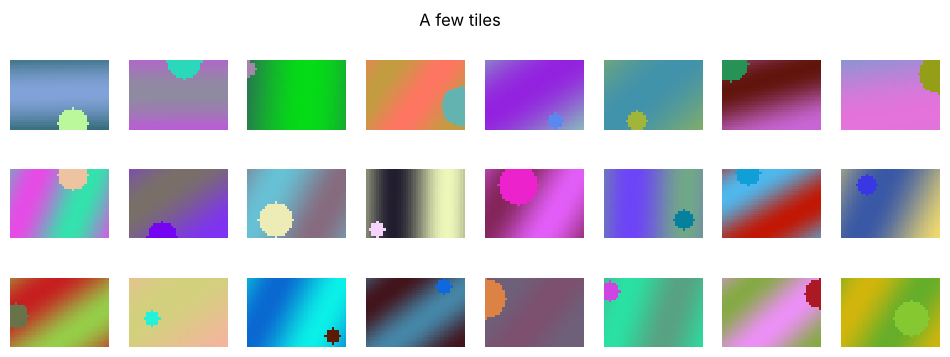

In [5]:
def load_pieces(params: Parameters):
    # Read the N tiles used to build the photomosaic.
    # All N images have the same size H x W x C (C = 3 for colour images).
    # Stores them in params.small_images with shape N x H x W x C.
    files = sorted(f for f in os.listdir(params.small_images_dir) if f.lower().endswith(params.image_type))
    if not files:
        raise FileNotFoundError('No *.%s files in %s' % (params.image_type, params.small_images_dir))
    images = [cv.imread(os.path.join(params.small_images_dir, f)) for f in files]

    if params.show_small_images:
        for i in range(min(100, len(images))):
            plt.subplot(10, 10, i + 1)
            show(images[i])
        plt.show()

    params.small_images = np.array(images)


params = Parameters(TEST_IMAGE)
load_pieces(params)
N, H, W, C = params.small_images.shape
print('N = %d tiles of size H x W = %d x %d, C = %d channels' % (N, H, W, C))

fig, axes = plt.subplots(3, 8, figsize=(12, 4))
for ax, tile in zip(axes.ravel(), params.small_images):
    show(tile, ax=ax)
plt.suptitle('A few tiles'); plt.show()

### Making the tile size "hexagon friendly"

In section 4 we will see that the hexagon rows are `3H/4` apart and odd rows are shifted by `W/2`.
If `H` is a multiple of 4 and `W` is a multiple of 2, **all these offsets are whole pixels**, so every hexagon in
the mosaic covers *exactly the same* pixel pattern and we can compute the mask **once** and reuse it.

If the tiles don't satisfy this, we resize them slightly (at most a couple of pixels). This is a common trick:
choose your units so the geometry becomes integer.

In [6]:
def make_tiles_hexagon_friendly(params: Parameters):
    # Resize tiles so that H % 4 == 0 and W % 2 == 0 (integer hexagon offsets).
    N, H, W, C = params.small_images.shape
    new_H = max(4, int(round(H / 4)) * 4)
    new_W = max(2, int(round(W / 2)) * 2)
    if (new_H, new_W) != (H, W):
        params.small_images = np.array([cv.resize(t, (new_W, new_H)) for t in params.small_images])
        print('Tiles resized from %dx%d to %dx%d' % (H, W, new_H, new_W))
    else:
        print('Tile size %dx%d is already hexagon friendly' % (H, W))


make_tiles_hexagon_friendly(params)
N, H, W, C = params.small_images.shape

Tile size 28x40 is already hexagon friendly


## 2. Hexagon geometry

### Choosing the orientation

There are two ways to put a hexagon in a box:

* **pointy-top**: a corner points up, rows of hexagons are horizontal and **every other row is shifted**;
* **flat-top**: a flat edge is on top, columns are vertical and every other column is shifted.

We use **pointy-top** (shifted rows), because it keeps the row-by-row loop we already know from the grid mosaic.

### Where are the corners?

We fit the hexagon inside the tile's `W x H` bounding box. With the image convention
(`x` to the right, `y` **down**), the 6 corners are:

```
            (W/2, 0)
             /    \
   (0, H/4) /      \ (W, H/4)
           |        |
           |        |
 (0, 3H/4) \        / (W, 3H/4)
             \    /
           (W/2, H)
```

* top and bottom corners are in the middle of the box: `x = W/2`;
* the vertical sides are the left and right edges of the box: `x = 0` and `x = W`;
* the vertical sides go from `H/4` to `3H/4`, so they are **half** of the total height.

**Why `H/4`?** In a *regular* hexagon with circumradius `R` the height is `2R` and every side has length `R`.
The vertical side therefore covers `R = H/2` of the height, centred, which leaves `H/4` above and below.

A regular pointy-top hexagon has width `W = √3·R = (√3/2)·H ≈ 0.866·H`. Our tiles have whatever aspect ratio
the dataset has, so our hexagon is a regular hexagon **stretched** horizontally or vertically. Stretching is a
linear map, and a linear map sends a tiling to a tiling, so everything below still works.

[[20.  0.]
 [40.  7.]
 [40. 21.]
 [20. 28.]
 [ 0. 21.]
 [ 0.  7.]]

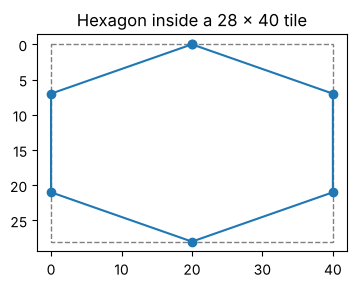

In [7]:
def hexagon_vertices(H, W):
    # Corners of a pointy-top hexagon that fits in a W x H box, in (x, y) pixel coordinates,
    # listed clockwise starting from the top corner.
    return np.array([
        [W / 2, 0],          # top
        [W,     H / 4],      # upper right
        [W,     3 * H / 4],  # lower right
        [W / 2, H],          # bottom
        [0,     3 * H / 4],  # lower left
        [0,     H / 4],      # upper left
    ], dtype=np.float64)


verts = hexagon_vertices(H, W)
print(verts)

plt.figure(figsize=(4, 4))
closed = np.vstack([verts, verts[:1]])
plt.plot(closed[:, 0], closed[:, 1], 'o-')
plt.gca().add_patch(plt.Rectangle((0, 0), W, H, fill=False, ls='--', color='gray'))
plt.gca().invert_yaxis(); plt.gca().set_aspect('equal')
plt.title('Hexagon inside a %d x %d tile' % (H, W)); plt.show()

## 3. The hexagon mask

The mask is a boolean `H x W` array: `True` if the pixel belongs to the hexagon. We derive it ourselves.

### Step 1: use the symmetry

The hexagon is symmetric left/right and top/bottom around its centre `(W/2, H/2)`.
So we move to **normalised, folded coordinates** where the hexagon becomes the same shape in every quadrant:

$$
a = \frac{|x - W/2|}{W/2}, \qquad b = \frac{|y - H/2|}{H/2}, \qquad a, b \in [0, 1]
$$

`a = 0` is the vertical centre line, `a = 1` the left/right box edge; same for `b` vertically.

### Step 2: only one slanted edge is left

In folded coordinates we only need the top-right quarter. Its slanted edge goes from the top corner
`(W/2, 0)` to `(W, H/4)`. Converting both points to `(a, b)`:

* `(W/2, 0)` → `(a, b) = (0, 1)`
* `(W, H/4)` → `(a, b) = (1, 1/2)`

The line through them is `b = 1 - a/2`. A pixel is inside if it is **below** this line (closer to the centre) and
inside the box:

$$
\boxed{\;a \le 1 \quad\text{and}\quad b \le 1 - \tfrac{a}{2}\;}
$$

That's the whole hexagon, written as two inequalities. (Without the folding you would write 6 half-plane
inequalities, one per edge; the folding is just a shortcut.)

### Step 3: which point of a pixel do we test?

Pixel `(row i, column j)` covers the square `[j, j+1] x [i, i+1]`. We test its **centre** `(j + 0.5, i + 0.5)`,
otherwise the mask is shifted by half a pixel and is not symmetric.

### Step 4: vectorise

Instead of two `for` loops over the pixels, we build arrays with the `x` and `y` of every pixel
(`np.meshgrid`) and evaluate the inequalities on all pixels at once.

In [8]:
def make_hexagon_mask(H, W):
    # Boolean H x W mask of a pointy-top hexagon inscribed in the tile (True = inside).
    x = np.arange(W) + 0.5                      # pixel centres along x
    y = np.arange(H) + 0.5                      # pixel centres along y
    xx, yy = np.meshgrid(x, y)                  # both have shape H x W

    a = np.abs(xx - W / 2) / (W / 2)            # 0 at the vertical centre line, 1 at the left/right edge
    b = np.abs(yy - H / 2) / (H / 2)            # 0 at the horizontal centre line, 1 at the top/bottom
    return (a <= 1) & (b <= 1 - a / 2)


mask = make_hexagon_mask(H, W)
print('mask shape:', mask.shape, '| pixels inside: %d of %d (%.1f%%)' % (mask.sum(), mask.size, 100 * mask.mean()))
print('expected area of a hexagon in its box: 3/4 = 75%')

mask shape: (28, 40) | pixels inside: 840 of 1120 (75.0%)
expected area of a hexagon in its box: 3/4 = 75%


### Checks

1. **Area**: the hexagon is its box minus 4 corner triangles, each of area `(W/2)(H/4)/2`, so the area is
   `WH - 4·WH/16 = 3/4·WH`. The printed percentage should be close to 75%.
2. **Shape**: plot it, and compare with OpenCV's polygon filler `cv.fillPoly` as an independent reference.
   A handful of pixels exactly on the slanted edges may differ (rounding rules), that's fine.
3. **Applying it to a tile**: multiplying a tile by the mask keeps only the hexagon.

pixels that differ from cv.fillPoly: 37 (3.3% of the tile)


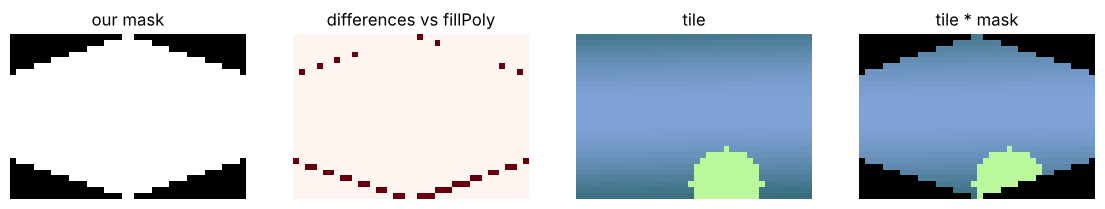

In [9]:
reference = np.zeros((H, W), np.uint8)
cv.fillPoly(reference, [np.round(verts).astype(np.int32)], 1)   # only used as a sanity check
diff = mask != reference.astype(bool)
print('pixels that differ from cv.fillPoly: %d (%.1f%% of the tile)' % (diff.sum(), 100 * diff.mean()))

tile = params.small_images[0]
fig, axes = plt.subplots(1, 4, figsize=(14, 3))
axes[0].imshow(mask, cmap='gray'); axes[0].set_title('our mask'); axes[0].axis('off')
axes[1].imshow(diff, cmap='Reds'); axes[1].set_title('differences vs fillPoly'); axes[1].axis('off')
show(tile, 'tile', axes[2])
show(tile * mask[:, :, None], 'tile * mask', axes[3])   # mask[:, :, None] broadcasts over the 3 channels
plt.show()

> 🧪 **Try it:** write `make_hexagon_mask_loops(H, W)` with two plain `for` loops and the same two inequalities,
> check that `np.array_equal` gives `True` against the vectorised version, and time both with `timeit`.
> Then try a flat-top hexagon: swap the roles of `a` and `b`.

## 4. The hexagonal grid

### Where do the hexagons go?

Look at two rows of pointy-top hexagons:

```
  /\  /\  /\  /\          row 0: hexagons at x = 0, W, 2W, ...
 |  ||  ||  ||  |
  \/\/\/\/\/\/\/\         row 1: shifted right by W/2
   |  ||  ||  ||  |
    \/  \/  \/  \/
```

* **Inside one row**, hexagons touch along their vertical sides, so the step is the full width: `dx = W`.
* **The next row** fits into the "V" notches of the previous row. It is shifted by **half a tile**, `W/2`,
  and it moves down by only **`3H/4`**: the bottom pointy corner of row `r` (from `3H/4` to `H`) overlaps
  with the top corner of row `r+1` (from `0` to `H/4`).

So the top-left corner of the bounding box of hexagon `(r, c)` is:

$$
y = r \cdot \tfrac{3H}{4}, \qquad x = c \cdot W + (r \bmod 2)\cdot\tfrac{W}{2}
$$

### Borders

The shifted rows and the pointy top/bottom leave half-hexagon gaps around the border of the image.
The cleanest fix: **pad** the image by one tile on every side, fill the padded canvas with whole hexagons, and
**crop** the padding at the end. No special cases for the borders.

In [10]:
def hex_grid_positions(canvas_h, canvas_w, H, W):
    # Top-left corners (y, x) and grid indices (r, c) of every hexagon whose box fits in the canvas.
    dy, dx = 3 * H // 4, W                      # integers thanks to make_tiles_hexagon_friendly
    positions = []
    r = 0
    while r * dy + H <= canvas_h:
        shift = (r % 2) * (W // 2)
        c = 0
        while shift + c * dx + W <= canvas_w:
            positions.append((r, c, r * dy, shift + c * dx))
            c += 1
        r += 1
    return positions


demo_h, demo_w = 5 * H, 6 * W
pos = hex_grid_positions(demo_h, demo_w, H, W)
print('%d hexagons fit in a %d x %d canvas' % (len(pos), demo_h, demo_w))

33 hexagons fit in a 140 x 240 canvas


### Check: no gaps

We place a copy of the mask at every position and count how many hexagons cover each pixel
(`coverage`). Away from the outer border every pixel must be covered at least once: **0 = gap** would be a bug.
Pixels on a shared slanted edge may be covered twice; that's harmless because the later tile just overwrites them.

gaps in the interior : 0
overlapping pixels   : 0 (pixels covered by two hexagons)


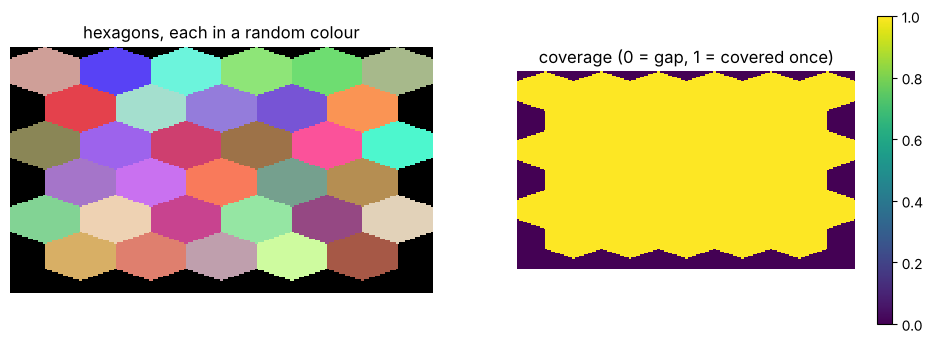

In [11]:
def coverage_map(canvas_h, canvas_w, H, W, mask):
    cov = np.zeros((canvas_h, canvas_w), np.int32)
    for r, c, y, x in hex_grid_positions(canvas_h, canvas_w, H, W):
        cov[y:y + H, x:x + W] += mask
    return cov


cov = coverage_map(demo_h, demo_w, H, W, mask)
inner = cov[H:-H, W:-W]     # ignore a one-tile margin with the ragged border: exactly the padding we'll use later
print('gaps in the interior :', (inner == 0).sum())
print('overlapping pixels   :', (inner > 1).sum(), '(pixels covered by two hexagons)')

colours = np.zeros((demo_h, demo_w, 3), np.uint8)
rng = np.random.default_rng(1)
for r, c, y, x in pos:
    patch = colours[y:y + H, x:x + W]
    patch[mask] = rng.integers(60, 255, 3)       # paint each hexagon in a random colour
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
show(colours, 'hexagons, each in a random colour', axes[0])
im = axes[1].imshow(cov, cmap='viridis'); axes[1].set_title('coverage (0 = gap, 1 = covered once)'); axes[1].axis('off')
plt.colorbar(im, ax=axes[1]); plt.show()

> 🧪 **Try it:** change `dy` to `H // 2` or the shift to `0` in `hex_grid_positions` and rerun the check:
> you'll see gaps or big overlaps appear. That's the best way to convince yourself that `3H/4` and `W/2` are right.

## 5. Matching: which tile goes into which hexagon?

### Masked mean colour

In class we compared the **mean colour of the whole patch** with the mean colour of each tile.
With hexagons, the corners of both the patch and the tile are thrown away, so the mean must be computed
**only over the pixels where `mask` is `True`**. Otherwise a tile with, say, a bright corner would look brighter
than it will appear in the mosaic.

NumPy boolean indexing does this in one line: `tile[mask]` has shape `(number_of_inside_pixels, 3)`.
For all tiles at once, `tiles[:, mask]` has shape `(N, inside_pixels, 3)`.

In [12]:
def convert_colors(images_bgr, color_space):
    # Convert an image, or a stack of images, to the colour space used for matching.
    if color_space == 'bgr':
        return images_bgr.astype(np.float32)
    if color_space == 'lab':
        shape = images_bgr.shape
        flat = images_bgr.reshape(-1, shape[-2], 3)            # cvtColor needs a 2D image: stack tiles vertically
        return cv.cvtColor(flat, cv.COLOR_BGR2LAB).reshape(shape).astype(np.float32)
    raise ValueError('unknown colour space %s' % color_space)


def get_mean_color_small_images_masked(params: Parameters, mask):
    # N x 3 array: mean colour of every tile, computed only inside the hexagon.
    tiles = convert_colors(params.small_images, params.color_space)
    return tiles[:, mask].mean(axis=1)


mean_color_pieces = get_mean_color_small_images_masked(params, mask)
print('mean_color_pieces:', mean_color_pieces.shape)
full_means = params.small_images.reshape(N, -1, 3).mean(axis=1)
print('average change from ignoring the corners: %.2f grey levels' % np.abs(full_means - mean_color_pieces).mean())

mean_color_pieces: (600, 3)
average change from ignoring the corners: 2.65 grey levels


### Nearest tile with a KD-tree

The class code, `get_sorted_distances`, computes the distance from the patch to **all N tiles** and sorts
them: `O(N log N)` work per patch. With thousands of hexagons and thousands of tiles that adds up.

A **KD-tree** (`scipy.spatial.cKDTree`) organises the N mean colours (points in 3D colour space) in a tree once,
then answers "which are the `k` closest points to this colour?" in about `O(log N)` per query. We also send
**all patches in one call**, which is much faster than a Python loop.

`tree.query(colours, k)` returns, for every query colour, the distances and the indices of its `k` nearest tiles,
sorted from closest to farthest. Let's check that it agrees with the brute-force method from class.

In [13]:
def get_sorted_distances(mean_color_patch, mean_color_pieces):
    # From class: brute force, distance to every tile then sort.
    dist = np.sum((mean_color_pieces - mean_color_patch) ** 2, axis=1)
    return np.argsort(dist)


tree = cKDTree(mean_color_pieces)
queries = np.random.uniform(0, 255, (5, 3))
_, idx_tree = tree.query(queries, k=3)
idx_brute = np.array([get_sorted_distances(q, mean_color_pieces)[:3] for q in queries])
print('KD-tree :', idx_tree.tolist())
print('brute   :', idx_brute.tolist())
print('same result:', np.array_equal(idx_tree, idx_brute))

many = np.random.uniform(0, 255, (5000, 3))
t_brute = timeit.timeit(lambda: [get_sorted_distances(q, mean_color_pieces)[0] for q in many], number=1)
t_tree = timeit.timeit(lambda: tree.query(many, k=1), number=1)
print('5000 queries: brute force %.3f s, KD-tree %.4f s' % (t_brute, t_tree))

KD-tree : [[394, 590, 372], [460, 282, 157], [46, 585, 289], [328, 291, 198], [143, 467, 559]]
brute   : [[394, 590, 372], [460, 282, 157], [46, 585, 289], [328, 291, 198], [143, 467, 559]]
same result: True


5000 queries: brute force 0.132 s, KD-tree 0.0029 s


### Different neighbours

With a smooth area (sky, a car door) many neighbouring hexagons have almost the same colour, get **the same
tile**, and the mosaic looks like wallpaper. A typical requirement is that **adjacent hexagons use different
tiles**.

We fill the grid row by row, left to right, so when we place hexagon `(r, c)` the neighbours already placed are:

* the **left** one in the same row: `(r, c-1)`
* the two **above** it in row `r-1`. Which ones depends on whether row `r` is shifted:
  * `r` even (not shifted): above-left `(r-1, c-1)` and above-right `(r-1, c)`
  * `r` odd (shifted right by `W/2`): above-left `(r-1, c)` and above-right `(r-1, c+1)`

At most 3 tiles are forbidden, so if we ask the KD-tree for the **4 nearest** tiles, at least one is allowed.

In [14]:
def placed_neighbours(r, c):
    # Grid indices of the (up to) 3 neighbours of hexagon (r, c) placed before it in raster order.
    if r % 2 == 0:
        return [(r, c - 1), (r - 1, c - 1), (r - 1, c)]
    return [(r, c - 1), (r - 1, c), (r - 1, c + 1)]


print('neighbours of (2, 3):', placed_neighbours(2, 3))
print('neighbours of (3, 3):', placed_neighbours(3, 3))

neighbours of (2, 3): [(2, 2), (1, 2), (1, 3)]
neighbours of (3, 3): [(3, 2), (2, 3), (2, 4)]


## 6. Masked compositing

To paste a tile at `(y, x)` we must change **only the pixels inside the hexagon** and leave the others
(which belong to the neighbouring hexagons) untouched. Boolean indexing on a view of the canvas does exactly that:

```python
region = canvas[y:y+H, x:x+W]   # a view: writing into it writes into the canvas
region[mask] = tile[mask]       # copy only the hexagon pixels
```

Equivalent formula: `region = mask * tile + (1 - mask) * region`, which you'll also see in alpha blending
(with a soft mask instead of a 0/1 mask).

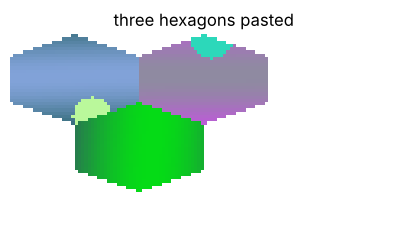

In [15]:
def paste_hexagon(canvas, tile, mask, y, x):
    H, W = mask.shape
    region = canvas[y:y + H, x:x + W]
    region[mask] = tile[mask]


canvas = np.full((2 * H, 3 * W, 3), 255, np.uint8)
paste_hexagon(canvas, params.small_images[0], mask, 0, 0)
paste_hexagon(canvas, params.small_images[1], mask, 0, W)
paste_hexagon(canvas, params.small_images[2], mask, 3 * H // 4, W // 2)   # second row, shifted
plt.figure(figsize=(5, 3)); show(canvas, 'three hexagons pasted'); plt.show()

## 7. Putting it together

### Dimensions

As in class, we fix the number of tiles horizontally and resize the input image so it is exactly
`num_pieces_horizontal * W` pixels wide, keeping its aspect ratio. In the hexagonal grid, rows are `3H/4` apart,
so the number of rows is about `height / (3H/4)`.

In [16]:
def compute_dimensions_hexagon(params: Parameters):
    hs, ws = params.small_images.shape[1:3]
    h, w = params.image.shape[:2]
    new_w = ws * params.num_pieces_horizontal
    new_h = int(round(h * new_w / w))           # keep the aspect ratio
    params.image_resized = cv.resize(params.image, (new_w, new_h))
    params.num_pieces_vertical = int(np.ceil(new_h / (3 * hs / 4)))   # approximate number of hexagon rows


def compute_dimensions(params: Parameters):
    # From class: square grid, the height must be a whole number of tiles.
    hs, ws, _ = params.small_images[0].shape
    h, w, _ = params.image.shape
    params.num_pieces_vertical = int(np.round(h * params.num_pieces_horizontal * ws / (hs * w)))
    params.image_resized = cv.resize(params.image, (ws * params.num_pieces_horizontal, hs * params.num_pieces_vertical))

### `add_pieces_hexagon`

The full algorithm, each line being one of the steps above:

1. compute the **mask** once (section 3);
2. **pad** the resized image by one tile on every side (section 4, borders);
3. list the **hexagon positions** on the padded canvas (section 4);
4. compute the **masked mean colour** of every patch under a hexagon, and of every tile (section 5);
5. ask the **KD-tree** for the 4 nearest tiles of every patch in one call (section 5);
6. walk through the hexagons in order, pick the closest tile that is **not used by a neighbour**,
   and **paste it through the mask** (sections 5 and 6);
7. **crop** the padding.

In [17]:
def add_pieces_hexagon(params: Parameters):
    start_time = timeit.default_timer()
    N, H, W, C = params.small_images.shape
    h, w = params.image_resized.shape[:2]
    mask = make_hexagon_mask(H, W)                                            # 1

    padded = cv.copyMakeBorder(params.image_resized, H, H, W, W, cv.BORDER_REFLECT)   # 2
    canvas = np.zeros_like(padded)
    positions = hex_grid_positions(padded.shape[0], padded.shape[1], H, W)    # 3

    if params.criterion == 'random':
        chosen = np.random.randint(0, N, len(positions))
        for (r, c, y, x), idx in zip(positions, chosen):
            paste_hexagon(canvas, params.small_images[idx], mask, y, x)

    elif params.criterion == 'mean-color-distance':
        padded_conv = convert_colors(padded, params.color_space)              # 4
        patch_means = np.array([padded_conv[y:y + H, x:x + W][mask].mean(axis=0) for _, _, y, x in positions])
        tile_means = get_mean_color_small_images_masked(params, mask)

        k = 4 if params.different_neighbours else 1                           # 5
        _, candidates = cKDTree(tile_means).query(patch_means, k=k)
        candidates = candidates.reshape(len(positions), k)

        used = {}                                                             # (r, c) -> tile index
        for (r, c, y, x), cand in zip(positions, candidates):                 # 6
            idx = cand[0]
            if params.different_neighbours:
                forbidden = {used.get(n) for n in placed_neighbours(r, c)}
                idx = next(i for i in cand if i not in forbidden)
            used[(r, c)] = idx
            paste_hexagon(canvas, params.small_images[idx], mask, y, x)
    else:
        raise ValueError('unknown criterion %s' % params.criterion)

    img_mosaic = canvas[H:H + h, W:W + w]                                     # 7
    print('Running time: %f s. (%d hexagons)' % (timeit.default_timer() - start_time, len(positions)))
    return img_mosaic

### `build_mosaic`

The class version with the hexagon branch filled in. The grid version from class is kept so we can compare.
`add_pieces_random` is stage 2 of the project.

In [18]:
def add_pieces_grid(params: Parameters):
    # From class (mean-colour version), for comparison.
    N, H, W, C = params.small_images.shape
    mean_color_pieces = params.small_images.reshape(N, -1, 3).mean(axis=1)
    img_mosaic = np.zeros(params.image_resized.shape, np.uint8)
    for i in range(params.num_pieces_vertical):
        for j in range(params.num_pieces_horizontal):
            patch = params.image_resized[i * H:(i + 1) * H, j * W:(j + 1) * W]
            idx = get_sorted_distances(patch.mean(axis=(0, 1)), mean_color_pieces)[0]
            img_mosaic[i * H:(i + 1) * H, j * W:(j + 1) * W] = params.small_images[idx]
    return img_mosaic


def build_mosaic(params: Parameters):
    load_pieces(params)
    if params.layout == 'grid':
        if params.hexagon:
            make_tiles_hexagon_friendly(params)
            compute_dimensions_hexagon(params)
            return add_pieces_hexagon(params)
        compute_dimensions(params)
        return add_pieces_grid(params)
    elif params.layout == 'random':
        raise NotImplementedError('stage 2: add_pieces_random')
    raise ValueError('Wrong option %s' % params.layout)

### Run it

Tile size 28x40 is already hexagon friendly


Running time: 0.626791 s. (4797 hexagons)


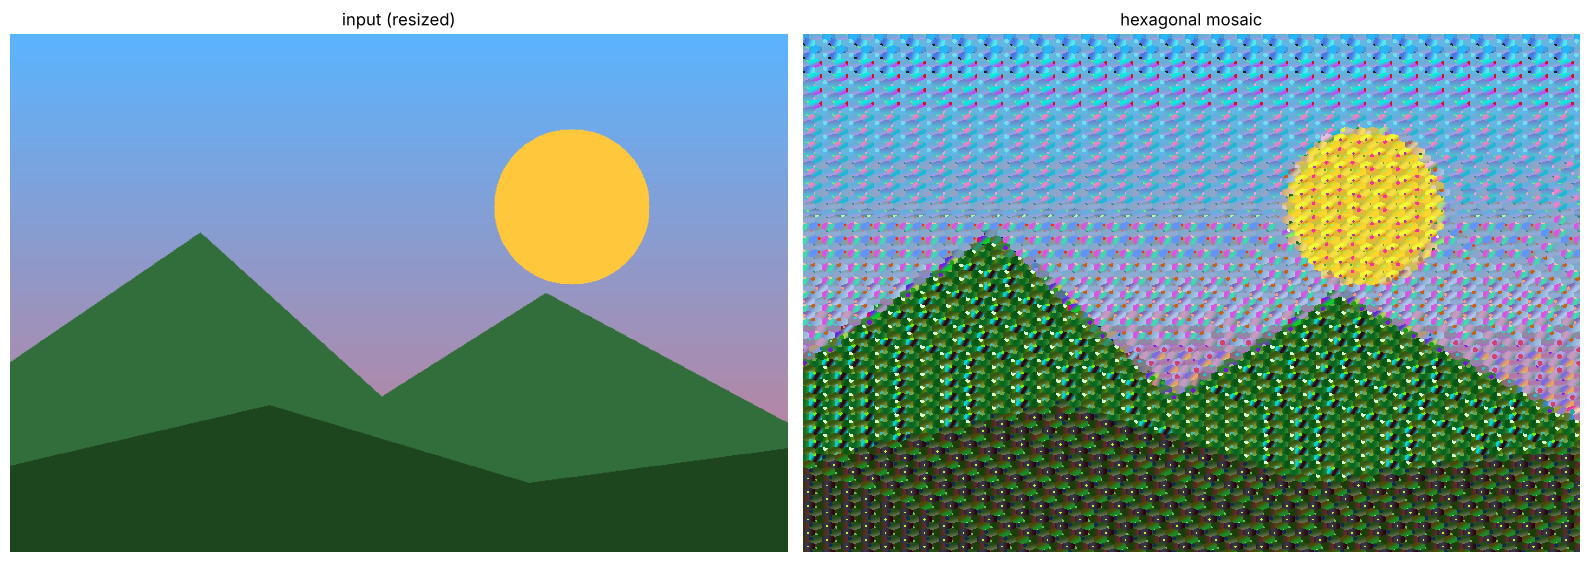

In [19]:
params = Parameters(TEST_IMAGE)
params.num_pieces_horizontal = 60
params.layout = 'grid'
params.criterion = 'mean-color-distance'
params.hexagon = True
params.different_neighbours = True
params.color_space = 'bgr'

img_mosaic = build_mosaic(params)
cv.imwrite(str(OUTPUT_DIR / 'mosaic_hexagon.png'), img_mosaic)

fig, axes = plt.subplots(1, 2, figsize=(16, 6))
show(params.image_resized, 'input (resized)', axes[0])
show(img_mosaic, 'hexagonal mosaic', axes[1])
plt.tight_layout(); plt.show()

Zoom in on a corner to see the individual hexagons (and that there are no black gaps, also at the borders):

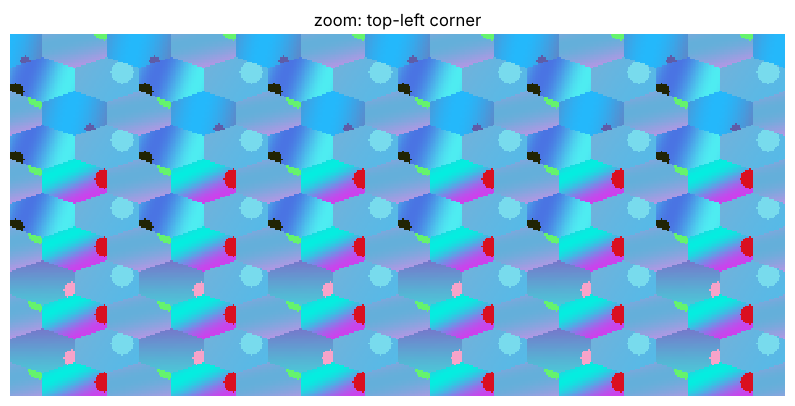

black (unfilled) pixels in the whole mosaic: 0


In [20]:
crop = img_mosaic[:8 * H, :12 * W]
plt.figure(figsize=(10, 6)); show(crop, 'zoom: top-left corner'); plt.show()
print('black (unfilled) pixels in the whole mosaic:', int((img_mosaic.sum(axis=2) == 0).sum()))

## 8. Experiments

Small changes that are worth comparing (and showing in the report):

* **grid vs hexagon** at the same number of tiles: hexagons follow curved contours better because there are
  no long straight horizontal/vertical seams;
* **`different_neighbours`** on vs off on a smooth area;
* **`color_space = 'lab'`**: in the Lab colour space, Euclidean distance is closer to how different two
  colours *look* to a human; it often helps on skin and sky;
* **`num_pieces_horizontal`**: more tiles = more detail, fewer = more "artistic".

Tile size 28x40 is already hexagon friendly


Running time: 0.695853 s. (4797 hexagons)
Tile size 28x40 is already hexagon friendly


Running time: 0.395077 s. (4797 hexagons)
Tile size 28x40 is already hexagon friendly


Running time: 0.502650 s. (4797 hexagons)


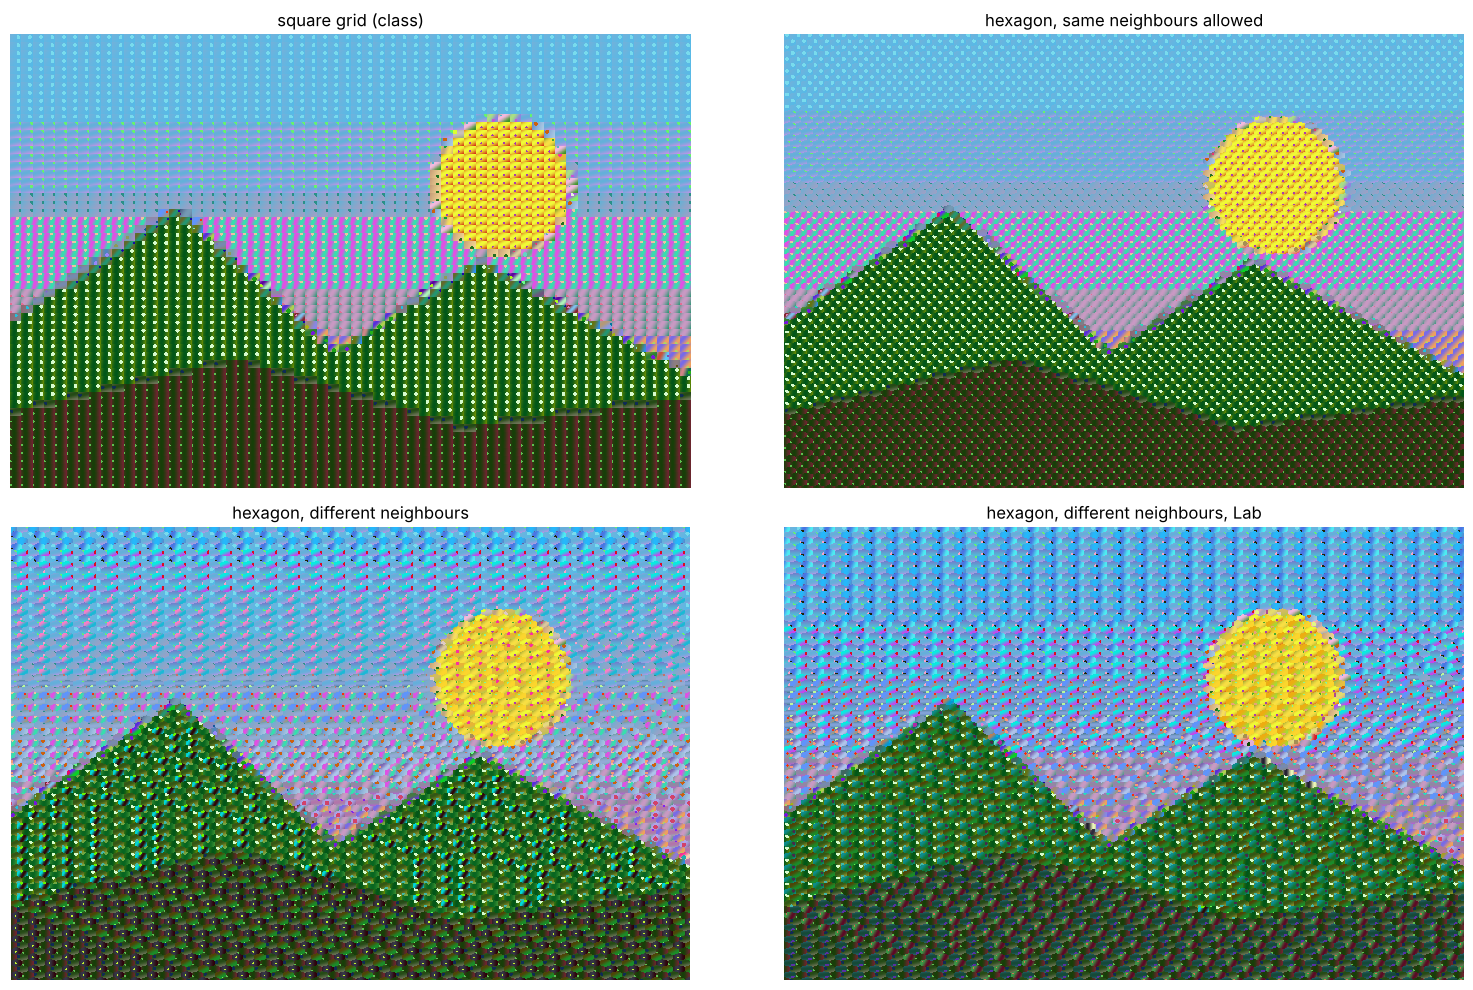

In [21]:
def run(**options):
    p = Parameters(TEST_IMAGE)
    p.num_pieces_horizontal = 60
    for key, value in options.items():
        setattr(p, key, value)
    return build_mosaic(p)


variants = {
    'square grid (class)': dict(hexagon=False),
    'hexagon, same neighbours allowed': dict(hexagon=True, different_neighbours=False),
    'hexagon, different neighbours': dict(hexagon=True, different_neighbours=True),
    'hexagon, different neighbours, Lab': dict(hexagon=True, different_neighbours=True, color_space='lab'),
}
fig, axes = plt.subplots(2, 2, figsize=(16, 10))
for ax, (name, opts) in zip(axes.ravel(), variants.items()):
    show(run(**opts), name, ax)
plt.tight_layout(); plt.show()

### What we wrote ourselves vs what comes from libraries

| Step | How |
|---|---|
| Hexagon corners | derived from the regular hexagon (`H/4`, `3H/4`, `W/2`) |
| Hexagon mask | own derivation: folded coordinates + one half-plane inequality, vectorised with NumPy |
| Hexagonal grid | own: `dy = 3H/4`, odd-row shift `W/2`, padding + crop for the borders, gap check |
| Masked mean colours | own: NumPy boolean indexing |
| Neighbour constraint | own: neighbour indices in the offset-row layout |
| Compositing | own: boolean indexing on a canvas view |
| Nearest colour search | `scipy.spatial.cKDTree` (checked against the brute-force class version) |
| Reading / resizing / padding / colour conversion | OpenCV (`imread`, `resize`, `copyMakeBorder`, `cvtColor`) |
| `cv.fillPoly` | only as an independent check of the mask, not used in the mosaic |

## Looking ahead: stage 2, random (non-grid) layout

Most of this notebook carries over:

* the **mask** and **`paste_hexagon`** work at *any* `(y, x)`, not only on grid positions. For square tiles in a random
  layout the mask is simply all `True`;
* instead of `hex_grid_positions`, positions are drawn at random, e.g. `y = np.random.randint(0, h_pad - H)`;
* keep a boolean **`filled`** map of the canvas and keep placing tiles until every pixel is covered
  (or pick the next position among the still-empty pixels so it finishes faster);
* the matching step is identical: masked mean colour of the patch at `(y, x)` → KD-tree query.